# So sánh Base và QLoRA

Chạy trên đúng 50 câu đã dùng để đánh giá baseline, giữ nguyên prompt, revision, cấu hình sinh, chuẩn hóa và chỉ số. Cell bên dưới yêu cầu adapter cuối đã xác minh.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

root = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "configs/inference.toml").is_file())
run = root / "runs/qwen3b-r8-local"
adapter = run / "final_adapter"
evaluation = root / "outputs/evaluation/qwen3b-r8"
env = os.environ.copy()
if (root / "artifacts/hf-cache").is_dir():
    env.setdefault("HF_HUB_CACHE", str(root / "artifacts/hf-cache"))
if not (adapter / "complete.json").is_file():
    print("Cần adapter đã huấn luyện để chạy đánh giá.")
else:
    command = [sys.executable, "-X", "utf8"]
    subprocess.run(command + ["scripts/summarize_training.py", "--adapter", str(adapter)], cwd=root, env=env, check=True)
    subprocess.run(command + ["scripts/evaluate_adapter.py", "--adapter", str(adapter), "--run-dir", str(evaluation)], cwd=root, env=env, check=True)

## Chỉ số, đường cong và phân tích lỗi

Chênh lệch tự động đo khớp văn bản. Kiểm tra xu hướng train/validation, đọc hai dự đoán của từng ca phân tích và chấm căn cứ độc lập trước khi kết luận pháp lý.

# Phase 5 · Base và QLoRA

50 câu hỏi theo đúng thứ tự Phase 3.

| Chỉ số | Base | QLoRA | Chênh lệch |
| --- | ---: | ---: | ---: |
| rouge_l | 0.228305 | 0.359918 | +0.131613 |
| token_f1 | 0.308649 | 0.400965 | +0.092316 |
| exact_match | 0.000000 | 0.000000 | +0.000000 |
| inference_time_s | 58.290165 | 27.078855 | — |

Hai lượt chạy dùng môi trường khác nhau. Thời gian chỉ được báo riêng cho từng lượt. Thời gian tính theo giây/câu.

| Loại câu hỏi | Số mẫu | F1 Base | F1 QLoRA |
| --- | ---: | ---: | ---: |
| authored | 10 | 0.3113 | 0.5390 |
| provision_lookup | 40 | 0.3080 | 0.3665 |

Chạm giới hạn sinh: 43/50 ở baseline và 23/50 ở QLoRA.

Token F1 tăng ở 32 câu, giảm ở 18 câu và bằng ở 0 câu.

Đánh giá pháp lý độc lập đang ở trạng thái `unverified`. Phiếu phân tích chọn 10 câu theo Token F1. Các nhãn lỗi cần đối chiếu nguồn gồm nội dung pháp lý sai, bịa căn cứ, thiếu ý, lạc đề, từ chối sai và quy định hết hiệu lực. Khả năng từ chối ngoài phạm vi cần tập kiểm tra riêng.

Validation loss theo bước: 10 → 1.0409, 20 → 0.9722, 30 → 0.9460, 40 → 0.9285, 50 → 0.9186, 60 → 0.9134, 70 → 0.9128, 80 → 0.9064, 90 → 0.9054, 100 → 0.9052. Giá trị thấp nhất 0.9052 ở bước 100. Đối chiếu đường cong train và validation khi nhận định overfitting.

### Chênh lệch F1 thấp nhất

- vn-road-55-77-1 (-0.2128). Tra cứu nội dung khoản 1 Điều 77 văn bản số 36/2024/QH15 về bảo đảm trật tự, an toàn giao thông đường bộ đối với trường hợp sử dụng tạm thời lòng đường, vỉa hè vào mục đích khác như thế nào? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=63)
- vn-road-55-74-1 (-0.1913). Về chỉ huy, điều khiển giao thông đường bộ, khoản 1 Điều 74 của Luật Trật tự, an toàn giao thông đường bộ số 36/2024/QH15 quy định gì? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=61)
- vn-road-65-15-3 (-0.1683). Về xây dựng, lắp đặt công trình hạ tầng kỹ thuật sử dụng chung với đường bộ, khoản 3 Điều 15 của Nghị định hướng dẫn Luật Đường bộ và Điều 77 Luật Trật tự, an toàn giao thông đường bộ số 165/2024/NĐ-CP quy định gì? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/8/65-vbhn-bxd.signed.pdf#page=19)
- vn-road-55-15-3 (-0.1279). Quy định về chuyển hướng xe tại khoản 3 Điều 15 văn bản số 36/2024/QH15 có nội dung gì? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=15)
- vn-road-55-56-4 (-0.0934). Về điều kiện của người điều khiển phương tiện tham gia giao thông đường bộ, khoản 4 Điều 56 của Luật Trật tự, an toàn giao thông đường bộ số 36/2024/QH15 quy định gì? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=45)

### Chênh lệch F1 cao nhất

- vn-road-49-55-1 (+0.5769). Kinh phí bảo trì và khai thác đường cao tốc do Nhà nước trực tiếp quản lý được bảo đảm từ nguồn nào? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/49-vbhn-vpqh.pdf#page=48)
- vn-road-38-8-1 (+0.4923). Xe chở người bốn bánh có gắn động cơ được chạy tối đa bao nhiêu trong phạm vi và thời gian được phép hoạt động? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2024/11/38-bgtvt.pdf#page=4)
- vn-road-55-15-1 (+0.4848). Những thao tác nào được coi là chuyển hướng xe? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=14)
- vn-road-55-26-1 (+0.4407). Xe cơ giới và xe thô sơ phải sử dụng đèn hoặc vật phát sáng thế nào trong hầm đường bộ? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=19)
- vn-road-49-69-1 (+0.4264). Về hoạt động vận tải người bệnh bằng xe ô tô cứu thương, khoản 1 Điều 69 của Luật Đường bộ số 35/2024/QH15 quy định gì? [Căn cứ](https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/49-vbhn-vpqh.pdf#page=57)


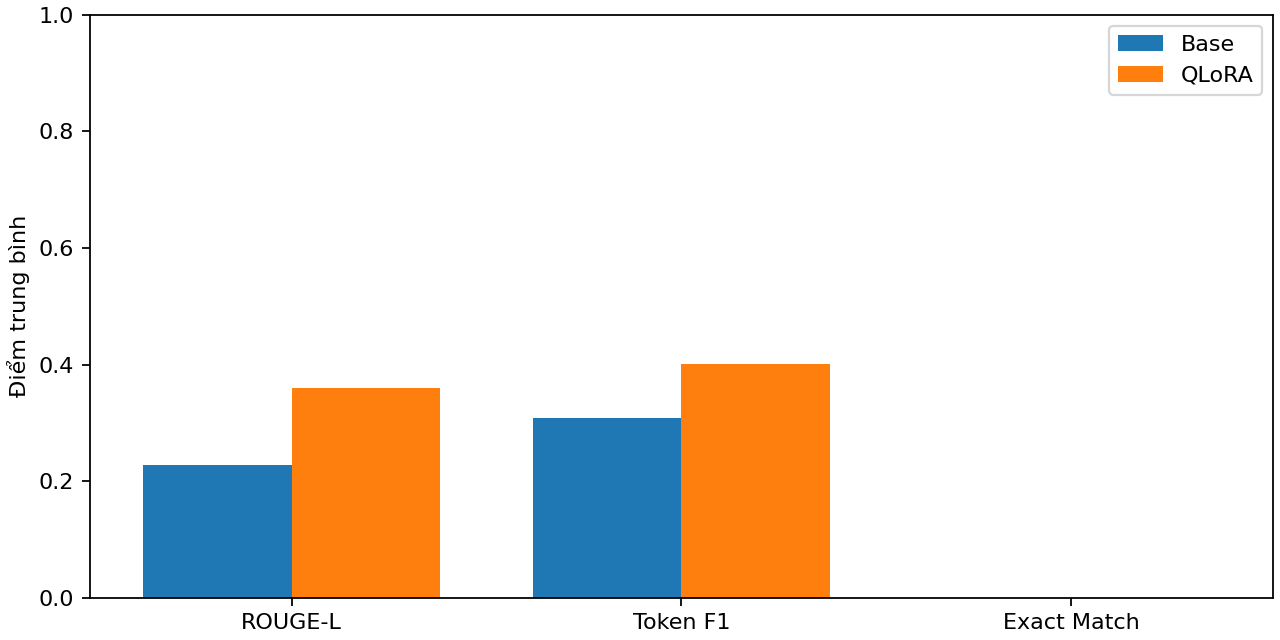

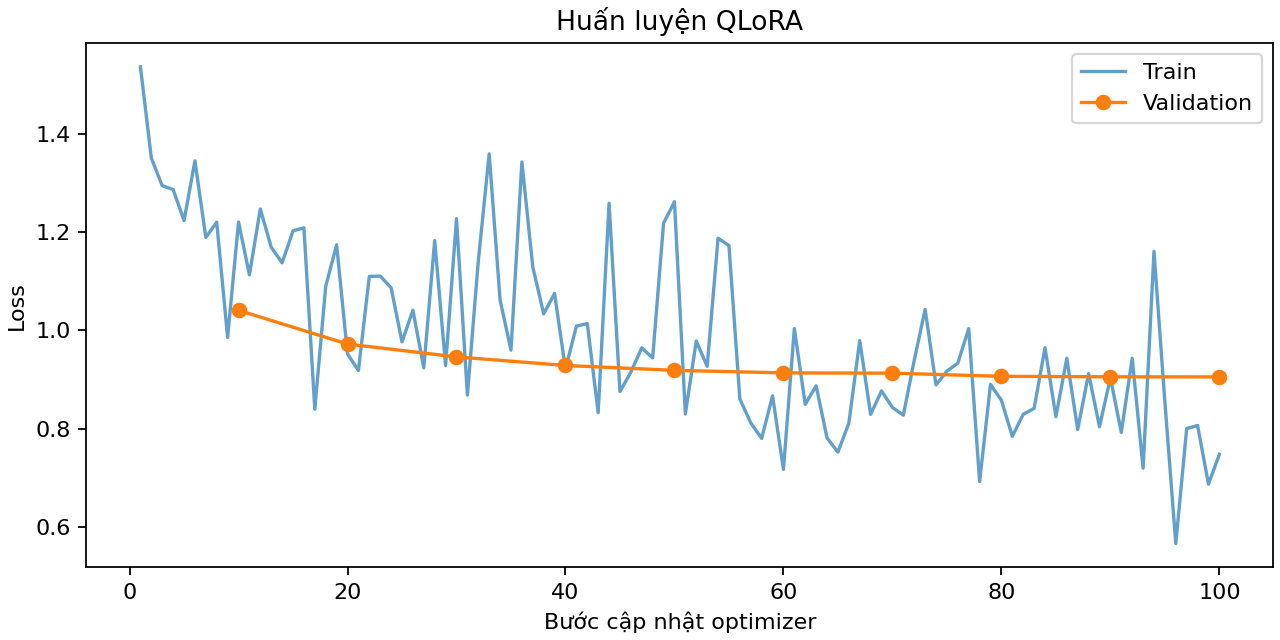

vn-road-55-77-1 Chênh lệch F1 thấp nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=63
vn-road-55-74-1 Chênh lệch F1 thấp nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=61
vn-road-65-15-3 Chênh lệch F1 thấp nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/8/65-vbhn-bxd.signed.pdf#page=19
vn-road-55-15-3 Chênh lệch F1 thấp nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=15
vn-road-55-56-4 Chênh lệch F1 thấp nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-vbhn-vpqh.pdf#page=45
vn-road-49-55-1 Chênh lệch F1 cao nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/49-vbhn-vpqh.pdf#page=48
vn-road-38-8-1 Chênh lệch F1 cao nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2024/11/38-bgtvt.pdf#page=4
vn-road-55-15-1 Chênh lệch F1 cao nhất unverified https://datafiles.chinhphu.vn/cpp/files/vbpq/2026/3/55-

In [2]:
import csv
from IPython.display import Image, Markdown, display

results = evaluation / "results"
if (results / "complete.json").is_file():
    display(Markdown((results / "comparison_report.md").read_text(encoding="utf-8")))
    for image in ("comparison_metrics.png", "training_loss.png"):
        display(Image(filename=str(results / image)))
    with (results / "error_analysis.csv").open(encoding="utf-8-sig", newline="") as handle:
        for row in csv.DictReader(handle):
            print(row["id"], row["selection"], row["review_status"], row["source_pdf_url"])
else:
    print("Chưa có kết quả so sánh.")